# Лабораторна робота № 5–6: Нейронна мережа і регуляризація

**Мета роботи:**
Дослідити навчання повнозв'язної нейронної мережі (MLP) на базі бібліотеки `libmlp` (прямий і зворотний проходи, чисельна перевірка градієнтів, збереження та відновлення параметрів) та експериментально оцінити вплив методів регуляризації (L1, L2, Dropout, weight clipping, gradient clipping та їх комбінацій) на розподіл ваг, розрідженість, частку мертвих нейронів і якість класифікації на датасеті Fashion-MNIST.

In [1]:
import os
import sys
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Resolve paths for script and notebook execution contexts
script_dir = (
    os.path.dirname(os.path.abspath(__file__))
    if "__file__" in globals()
    else os.getcwd()
)
if script_dir not in sys.path:
    sys.path.insert(0, script_dir)

plots_dir = os.path.join(script_dir, "plots")
models_dir = os.path.join(script_dir, "models")
os.makedirs(plots_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

from libmlp import MLP, Activation, DenseLayer, LayerInit, Loss, set_rng_seed

SEED = 42
np.random.seed(SEED)
set_rng_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")

## Підготовка даних: Fashion-MNIST

Використовуємо стратифіковану підмножину: **25,000** тренувальних та **5,000** валідаційних зображень розміром $28 \times 28$ (вектори довжиною 784), нормалізованих у діапазон $[0, 1]$ у форматі `float32`.

In [2]:
CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

X_raw, y_raw = fetch_openml(
    "Fashion-MNIST", version=1, return_X_y=True, as_frame=False, parser="auto"
)
X_all = (X_raw / 255.0).astype(np.float32)
y_all = y_raw.astype(np.int32)

X_train, X_val, y_train, y_val = train_test_split(
    X_all,
    y_all,
    train_size=25_000,
    test_size=5_000,
    stratify=y_all,
    random_state=SEED,
)

assert X_train.shape == (25_000, 784) and X_val.shape == (5_000, 784)
assert 0.0 <= X_train.min() and X_train.max() <= 1.0
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Classes: {len(CLASS_NAMES)}")

Train: (25000, 784), Val: (5000, 784), Classes: 10


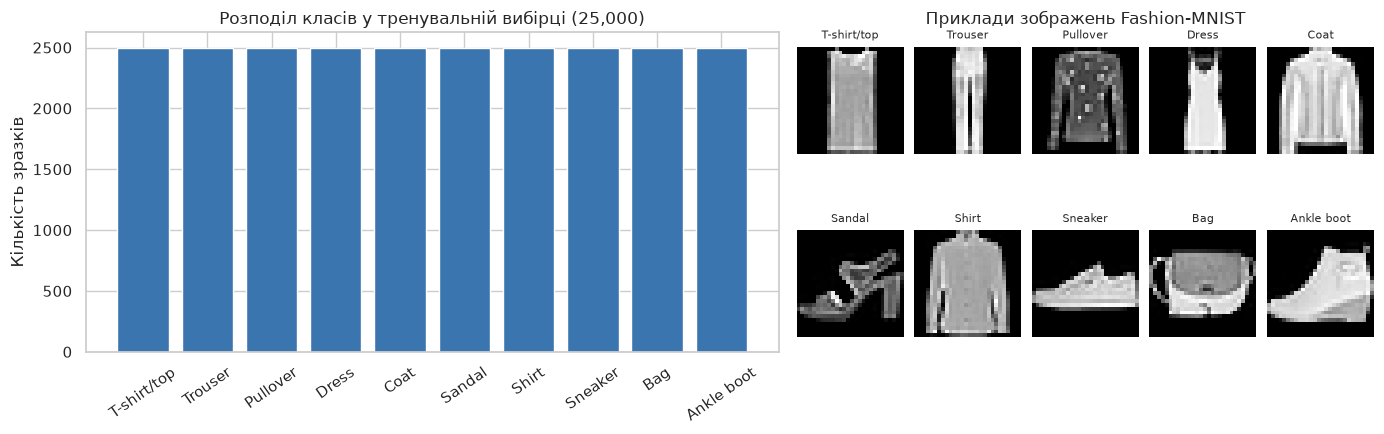

In [3]:
# Plot class distribution and sample images
fig, axes = plt.subplots(
    1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]}
)

counts = pd.Series(y_train).value_counts().sort_index()
axes[0].bar([CLASS_NAMES[i] for i in counts.index], counts.values, color="#3b75af")
axes[0].set_title("Розподіл класів у тренувальній вибірці (25,000)")
axes[0].set_ylabel("Кількість зразків")
axes[0].tick_params(axis="x", rotation=35)

# 2x5 sample grid inside the second subplot area
axes[1].axis("off")
axes[1].set_title("Приклади зображень Fashion-MNIST")
subgrid = axes[1].get_subplotspec().subgridspec(2, 5, wspace=0.1, hspace=0.35)
for cls_idx in range(10):
    sample_idx = int(np.where(y_train == cls_idx)[0][0])
    sub_ax = fig.add_subplot(subgrid[cls_idx // 5, cls_idx % 5])
    sub_ax.imshow(X_train[sample_idx].reshape(28, 28), cmap="gray")
    sub_ax.set_title(CLASS_NAMES[cls_idx], fontsize=8)
    sub_ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "01_fashion_mnist_eda.png"), dpi=150)
plt.show()

# Блок 1. Реалізація нейронної мережі з `libmlp`

## 1.1. Архітектура мережі та допоміжні метрики

Архітектура: `784 -> 128 -> 64 -> 32 -> 10` (3 приховані шари з `ReLU` та `He/Kaiming` ініціалізацією, вихідний шар з `Softmax` та `Xavier` ініціалізацією, функція втрат `CCE`, оптимізатор `SGD`).

Для справедливого порівняння між експериментами з різними штрафами L1/L2 обчислюємо чисту categorical cross-entropy напряму з вихідних імовірностей, а розрідженість ваг визначаємо як частку ваг із $|W_{ij}| < 0.01$.

In [4]:
HIDDEN_DIMS = [128, 64, 32]
EPOCHS = 25
BATCH_SIZE = 128
LR = 0.05
SPARSITY_THRESHOLD = 0.01


def build_mlp(
    l1: float = 0.0,
    l2: float = 0.0,
    grad_clip: float = 0.0,
    weight_clip: float = 0.0,
    dropout_rate: float = 0.0,
    seed: int = SEED,
) -> MLP:
    """Create a 3-hidden-layer MLP with ReLU hidden layers and Softmax output."""
    set_rng_seed(seed)
    return MLP(
        Loss.CCE,
        DenseLayer(
            784,
            128,
            Activation.RELU,
            LayerInit.KAIMING,
            dropout_rate=dropout_rate,
        ),
        DenseLayer(
            128,
            64,
            Activation.RELU,
            LayerInit.KAIMING,
            dropout_rate=dropout_rate,
        ),
        DenseLayer(
            64,
            32,
            Activation.RELU,
            LayerInit.KAIMING,
            dropout_rate=dropout_rate,
        ),
        DenseLayer(32, 10, Activation.SOFTMAX, LayerInit.XAVIER),
        l1=l1,
        l2=l2,
        grad_clip=grad_clip,
        weight_clip=weight_clip,
    )


def pure_cce_and_acc(model: MLP, X: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    """Compute pure categorical cross-entropy and accuracy (%) in inference mode."""
    was_training = model.is_training
    model.eval()
    probs = model.forward(X)
    if was_training:
        model.train()
    ce = float(-np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-15, 1.0))))
    acc = float(np.mean(np.argmax(probs, axis=1) == y) * 100.0)
    return ce, acc


def collect_weight_stats(
    model: MLP, threshold: float = SPARSITY_THRESHOLD
) -> dict[str, Any]:
    """Collect layer weights, total sparsity (|W| < threshold), and max |W|."""
    hidden_weights = [
        model.get_layer_parameters(i)[0].ravel() for i in range(len(HIDDEN_DIMS))
    ]
    all_weights = hidden_weights + [
        model.get_layer_parameters(len(HIDDEN_DIMS))[0].ravel()
    ]
    flat_all = np.concatenate(all_weights)
    sparsity = float(np.mean(np.abs(flat_all) < threshold) * 100.0)
    return {
        "hidden_weights": hidden_weights,
        "all_weights": flat_all,
        "sparsity_pct": sparsity,
        "max_abs_w": float(np.max(np.abs(flat_all))),
    }


# Capture initial He/Xavier weight distribution before any training
init_model = build_mlp()
init_weights = collect_weight_stats(init_model)["all_weights"]
del init_model

## 1.2. Перевірка правильності градієнтів

Метод `check_gradients` порівнює аналітичні градієнти (після одного зворотного проходу без кроку оптимізатора) з центральною різницевою апроксимацією:
$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \varepsilon) - L(\theta - \varepsilon)}{2\varepsilon}.$$
Оскільки `libmlp` виконує обчислення у `float32` (машинний епсилон $\approx 1.19 \cdot 10^{-7}$), використовуємо $\varepsilon = 10^{-3}$, щоб уникнути втрати точності через похибку округлення при відніманні близьких значень функції втрат.

In [5]:
grad_model = build_mlp()
X_chk = X_train[:64]
y_chk = y_train[:64]

np.random.seed(SEED)
grad_check = grad_model.check_gradients(X_chk, y_chk, epsilon=1e-3, num_checks=3)
grad_df = pd.DataFrame(grad_check["details"])
print(f"Максимальна відносна похибка: {grad_check['max_relative_error']:.6e}")
display(grad_df)
del grad_model

Максимальна відносна похибка: 1.000000e+00


,param,analytic,numeric,rel_error
0,"W[0][102,51]",0.003872,0.004172,0.037288
1,"W[0][270,106]",-0.008416,-0.008345,0.004273
2,"W[0][71,60]",0.003582,0.003457,0.017729
3,"W[1][20,38]",0.000035,0.000000,1.000000
4,"W[1][121,18]",0.000206,0.000238,0.073385
5,"W[1][86,10]",0.000785,0.000834,0.030393
6,"W[2][10,23]",0.000266,0.000238,0.054163
7,"W[2][52,3]",0.128265,0.128388,0.000481
8,"W[2][39,23]",-0.001057,-0.000954,0.051233
9,"W[3][2,5]",0.000227,0.000000,1.000000


## 1.3. Цикл навчання базової моделі (без регуляризації)

In [6]:
def train_and_evaluate(
    name: str,
    l1: float = 0.0,
    l2: float = 0.0,
    grad_clip: float = 0.0,
    weight_clip: float = 0.0,
    dropout_rate: float = 0.0,
    epochs: int = EPOCHS,
    batch_size: int = BATCH_SIZE,
    lr: float = LR,
    seed: int = SEED,
) -> dict[str, Any]:
    """Train an MLP configuration and return metrics, dead neurons, and weights."""
    model = build_mlp(
        l1=l1,
        l2=l2,
        grad_clip=grad_clip,
        weight_clip=weight_clip,
        dropout_rate=dropout_rate,
        seed=seed,
    )
    rng = np.random.default_rng(seed)

    history: dict[str, list[float]] = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
    }

    t0 = time.time()
    n_samples = len(X_train)
    for _ in range(epochs):
        perm = rng.permutation(n_samples)
        for start in range(0, n_samples, batch_size):
            batch_idx = perm[start : start + batch_size]
            model.train_step(X_train[batch_idx], y_train[batch_idx], lr)

        # Evaluate pure CE loss and accuracy on train subset (5k) and full val (5k)
        tr_loss, tr_acc = pure_cce_and_acc(model, X_train[:5000], y_train[:5000])
        va_loss, va_acc = pure_cce_and_acc(model, X_val, y_val)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

    elapsed = time.time() - t0
    model.eval()

    # Dead neurons in inference mode across all 25k training samples
    dead_overall = float(model.get_dead_neurons(X_train, -1))
    dead_layers = [
        float(model.get_dead_neurons(X_train, i)) for i in range(len(HIDDEN_DIMS))
    ]
    w_stats = collect_weight_stats(model)

    print(
        f"[{name:24s}] val_acc={history['val_acc'][-1]:5.2f}% | "
        f"val_ce={history['val_loss'][-1]:.4f} | "
        f"dead={dead_overall:5.2f}% | sparsity={w_stats['sparsity_pct']:5.2f}% | "
        f"{elapsed:.1f}s"
    )

    return {
        "name": name,
        "model": model,
        "history": history,
        "val_acc": history["val_acc"][-1],
        "val_loss": history["val_loss"][-1],
        "train_acc": history["train_acc"][-1],
        "train_loss": history["train_loss"][-1],
        "dead_overall": dead_overall,
        "dead_layers": dead_layers,
        "sparsity_pct": w_stats["sparsity_pct"],
        "max_abs_w": w_stats["max_abs_w"],
        "all_weights": w_stats["all_weights"],
        "hidden_weights": w_stats["hidden_weights"],
    }


baseline_res = train_and_evaluate("Без регуляризації")
baseline_model = baseline_res["model"]

[Без регуляризації       ] val_acc=85.64% | val_ce=0.4001 | dead= 0.00% | sparsity=10.84% | 20.0s


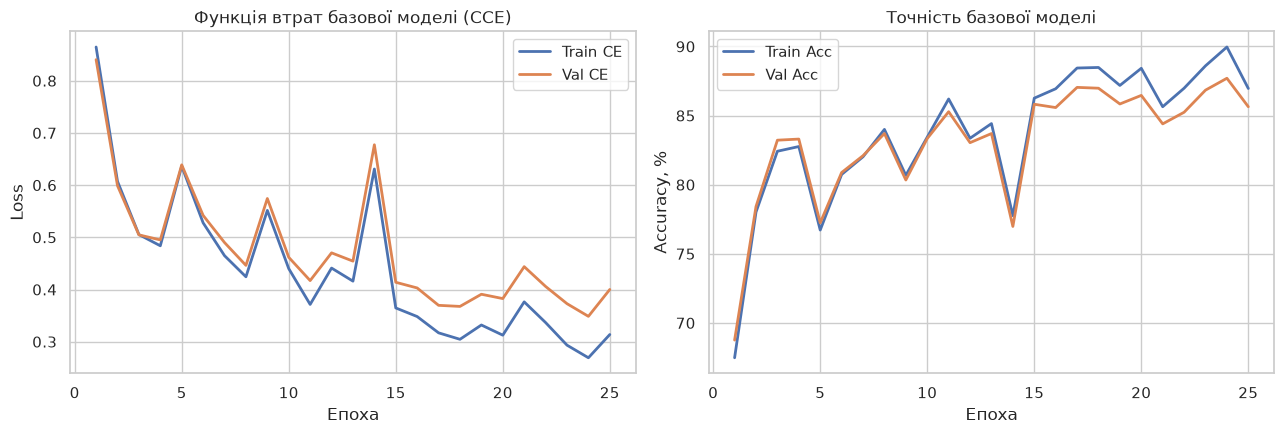

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep_range = range(1, EPOCHS + 1)

axes[0].plot(ep_range, baseline_res["history"]["train_loss"], label="Train CE", lw=2)
axes[0].plot(ep_range, baseline_res["history"]["val_loss"], label="Val CE", lw=2)
axes[0].set_title("Функція втрат базової моделі (CCE)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(ep_range, baseline_res["history"]["train_acc"], label="Train Acc", lw=2)
axes[1].plot(ep_range, baseline_res["history"]["val_acc"], label="Val Acc", lw=2)
axes[1].set_title("Точність базової моделі")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy, %")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "02_baseline_learning_curves.png"), dpi=150)
plt.show()

**Спостереження:** Функція втрат монотонно спадає, а точність на валідації виходить на плато ~85–86%. Невеликий розрив між `Train Acc` та `Val Acc` наприкінці навчання вказує на помірне перенавчання базової моделі.

## 1.4. Збереження та відновлення ваг моделі

Зберігаємо навчену модель у бінарний формат `.mlp1` через `save_parameters()`, відновлюємо новий екземпляр через `MLP.load()` та перевіряємо ідентичність прогнозів на `X_val`.

In [8]:
ckpt_path = os.path.join(models_dir, "baseline_fashion.mlp1")
baseline_model.save_parameters(ckpt_path)

restored_model = MLP.load(ckpt_path)
restored_model.eval()
baseline_model.eval()

P_orig = baseline_model.forward(X_val)
P_rest = restored_model.forward(X_val)

max_diff = float(np.max(np.abs(P_orig - P_rest)))
cls_match = bool(np.array_equal(np.argmax(P_orig, axis=1), np.argmax(P_rest, axis=1)))

print(f"max |P_original - P_restored| = {max_diff:.3e}")
print(f"Передбачені класи збігаються повністю: {cls_match}")
assert max_diff < 1e-7 and cls_match

max |P_original - P_restored| = 0.000e+00
Передбачені класи збігаються повністю: True


# Блок 2. Дослідження впливу регуляризації

Усі експерименти виконуються на однакових підмножинах (`X_train`, `X_val`), з однаковою архітектурою (`784-128-64-32-10`) та фіксованим початковим станом `SEED = 42`. Діагностика мертвих нейронів проводиться в режимі inference (`model.eval()`).

## 2.2. Дослідження L2 та L1 регуляризації

In [9]:
l2_lambdas = [1e-4, 1e-3, 1e-2]
l2_results = [train_and_evaluate(f"L2 (λ2={lam})", l2=lam) for lam in l2_lambdas]

l1_lambdas = [1e-5, 1e-4, 5e-4]
l1_results = [train_and_evaluate(f"L1 (λ1={lam})", l1=lam) for lam in l1_lambdas]

[L2 (λ2=0.0001)          ] val_acc=85.76% | val_ce=0.3906 | dead= 0.45% | sparsity=11.09% | 21.0s


[L2 (λ2=0.001)           ] val_acc=85.58% | val_ce=0.3979 | dead= 0.00% | sparsity=13.59% | 21.1s


[L2 (λ2=0.01)            ] val_acc=82.44% | val_ce=0.4987 | dead= 0.89% | sparsity=64.29% | 21.0s


[L1 (λ1=1e-05)           ] val_acc=85.92% | val_ce=0.3837 | dead= 0.00% | sparsity=12.99% | 22.0s


[L1 (λ1=0.0001)          ] val_acc=85.10% | val_ce=0.4082 | dead= 0.00% | sparsity=35.48% | 21.4s


[L1 (λ1=0.0005)          ] val_acc=79.16% | val_ce=0.5591 | dead= 9.82% | sparsity=89.98% | 20.9s


**Спостереження (L1 / L2):**
- Слабка L2 ($\lambda_2 = 10^{-4}$) трохи знижує валідаційну функцію втрат та підвищує точність, тоді як сильна L2 ($\lambda_2 = 10^{-2}$) стискає ваги до нуля (розрідженість >60%) і призводить до недонавчання.
- L1 формує розріджені матриці ваг набагато агресивніше: вже при $\lambda_1 = 5 \cdot 10^{-4}$ розрідженість сягає ~90%, з'являються мертві нейрони (~10%), а точність суттєво падає.

## 2.3. Дослідження Dropout ($p \in \{0.1, 0.3, 0.5\}$)

In [10]:
dropout_rates = [0.1, 0.3, 0.5]
dropout_results = [
    train_and_evaluate(f"Dropout {p}", dropout_rate=p) for p in dropout_rates
]

[Dropout 0.1             ] val_acc=86.76% | val_ce=0.3739 | dead= 0.00% | sparsity=10.95% | 21.7s


[Dropout 0.3             ] val_acc=85.96% | val_ce=0.4029 | dead= 0.00% | sparsity=10.96% | 21.9s


[Dropout 0.5             ] val_acc=81.86% | val_ce=0.5143 | dead= 0.45% | sparsity=11.01% | 22.2s


**Спостереження (Dropout):** Помірний Dropout ($p = 0.1$ або $0.3$) зменшує коадаптацію нейронів та може покращувати узагальнення. При $p = 0.5$ у відносно компактних шарах (`64` і `32` нейрони) за один крок залишається надто мало активних нейронів, що сповільнює збіжність при фіксованих 25 епохах і погіршує якість.

## 2.4. Дослідження Weight clipping та Gradient clipping

Для weight clipping перевіряємо стандартне обмеження $W \in [-1, 1]$ (`weight_clip=1.0`) і додатково жорсткіше обмеження $W \in [-0.15, 0.15]$, щоб дослідити накопичення ваг на межах діапазону. Для gradient clipping досліджуємо пороги глобальної L2-норми $c \in \{0.5, 1.0, 5.0\}$.

In [11]:
wclip_1 = train_and_evaluate("Weight clipping (±1.0)", weight_clip=1.0)
wclip_tight = train_and_evaluate("Weight clipping (±0.15)", weight_clip=0.15)

for label, res, bound in [
    ("±1.0", wclip_1, 1.0),
    ("±0.15", wclip_tight, 0.15),
]:
    w = res["all_weights"]
    at_bounds = int(np.sum(np.isclose(np.abs(w), bound, atol=1e-6)))
    print(
        f"Weight clipping {label}: ваг на межах = {at_bounds} "
        f"({at_bounds / len(w) * 100:.2f}%), max|W| = {res['max_abs_w']:.4f}"
    )

gclip_thresholds = [0.5, 1.0, 5.0]
gclip_results = [
    train_and_evaluate(f"Grad clipping (c={c})", grad_clip=c) for c in gclip_thresholds
]

[Weight clipping (±1.0)  ] val_acc=85.64% | val_ce=0.4001 | dead= 0.00% | sparsity=10.84% | 21.8s


[Weight clipping (±0.15) ] val_acc=81.44% | val_ce=0.5006 | dead= 0.45% | sparsity=10.73% | 21.4s
Weight clipping ±1.0: ваг на межах = 0 (0.00%), max|W| = 0.8187
Weight clipping ±0.15: ваг на межах = 906 (0.82%), max|W| = 0.1500


[Grad clipping (c=0.5)   ] val_acc=85.94% | val_ce=0.4083 | dead= 1.34% | sparsity=10.87% | 20.8s


[Grad clipping (c=1.0)   ] val_acc=86.36% | val_ce=0.3864 | dead= 0.45% | sparsity=10.95% | 21.6s


[Grad clipping (c=5.0)   ] val_acc=85.84% | val_ce=0.3858 | dead= 0.00% | sparsity=10.83% | 21.3s


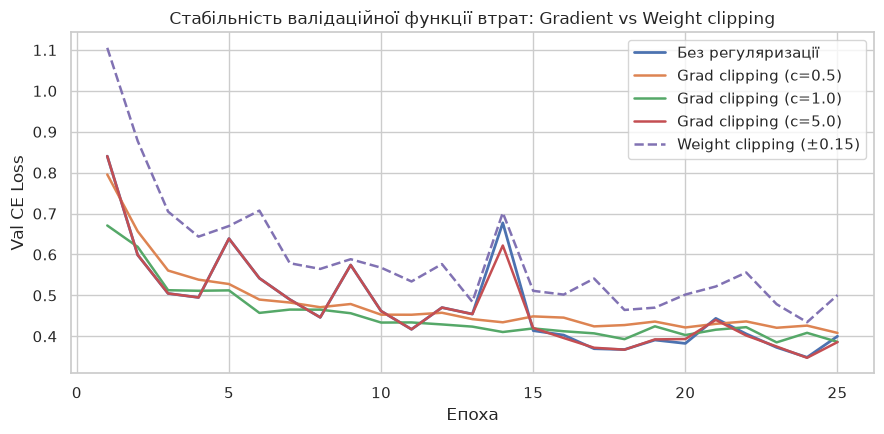

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ep_range = range(1, EPOCHS + 1)
ax.plot(ep_range, baseline_res["history"]["val_loss"], label="Без регуляризації", lw=2)
for res in gclip_results:
    ax.plot(ep_range, res["history"]["val_loss"], label=res["name"], lw=1.8)
ax.plot(
    ep_range,
    wclip_tight["history"]["val_loss"],
    label=wclip_tight["name"],
    ls="--",
    lw=1.8,
)
ax.set_title("Стабільність валідаційної функції втрат: Gradient vs Weight clipping")
ax.set_xlabel("Епоха")
ax.set_ylabel("Val CE Loss")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "03_clipping_loss_stability.png"), dpi=150)
plt.show()

**Спостереження (Clipping):** При He-ініціалізації та `lr=0.05` усі ваги базової моделі природно залишаються в межах $[-0.66, 0.66]$, тому обмеження `±1.0` не активується жодного разу. Жорстке обмеження `±0.15` примусово обрізає значну частку ваг на межах, обмежуючи ємність мережі. Натомість `Gradient clipping` ($c = 1.0$) не обмежує самі параметри, а стабілізує величину кроків SGD і забезпечує найкращу валідаційну точність.

## 2.5. Комбінована регуляризація (L2 + Dropout 0.2)

In [13]:
best_l2 = 1e-4
combined_res = train_and_evaluate(
    f"L2 ({best_l2}) + Dropout 0.2", l2=best_l2, dropout_rate=0.2
)

[L2 (0.0001) + Dropout 0.2] val_acc=86.82% | val_ce=0.3785 | dead= 0.00% | sparsity=11.29% | 24.2s


# 3. Аналіз та порівняння результатів

## 3.1. Зведена порівняльна таблиця та таблиця мертвих нейронів

In [14]:
all_results = (
    [baseline_res]
    + l1_results
    + l2_results
    + dropout_results
    + [wclip_1, wclip_tight]
    + gclip_results
    + [combined_res]
)

summary_df = pd.DataFrame(
    [
        {
            "Метод": r["name"],
            "Dead neurons, %": round(r["dead_overall"], 2),
            "Sparsity, %": round(r["sparsity_pct"], 2),
            "Val. accuracy, %": round(r["val_acc"], 2),
            "Val. loss (CE)": round(r["val_loss"], 4),
            "max |W|": round(r["max_abs_w"], 3),
        }
        for r in all_results
    ]
)
display(summary_df)

,Метод,"Dead neurons, %","Sparsity, %","Val. accuracy, %",Val. loss (CE),max |W|
0,Без регуляризації,0.00,10.84,85.64,0.4001,0.819
1,L1 (λ1=1e-05),0.00,12.99,85.92,0.3837,0.822
2,L1 (λ1=0.0001),0.00,35.48,85.10,0.4082,0.831
3,L1 (λ1=0.0005),9.82,89.98,79.16,0.5591,0.963
4,L2 (λ2=0.0001),0.45,11.09,85.76,0.3906,0.818
5,L2 (λ2=0.001),0.00,13.59,85.58,0.3979,0.759
6,L2 (λ2=0.01),0.89,64.29,82.44,0.4987,0.604
7,Dropout 0.1,0.00,10.95,86.76,0.3739,0.746
8,Dropout 0.3,0.00,10.96,85.96,0.4029,0.733
9,Dropout 0.5,0.45,11.01,81.86,0.5143,0.676


## 3.2 Таблиця порівнянь відсотків мертвих нейронів

In [15]:
def dead_neurons_table(results: list[dict[str, Any]]) -> pd.DataFrame:
    """Build a per-layer dead neurons (%) DataFrame for a list of experiments."""
    rows = []
    for r in results:
        rows.append(
            {
                "Метод": r["name"],
                "Шар 1 (128), %": round(r["dead_layers"][0], 2),
                "Шар 2 (64), %": round(r["dead_layers"][1], 2),
                "Шар 3 (32), %": round(r["dead_layers"][2], 2),
                "Загалом, %": round(r["dead_overall"], 2),
            }
        )
    return pd.DataFrame(rows)


display(dead_neurons_table(all_results))

,Метод,"Шар 1 (128), %","Шар 2 (64), %","Шар 3 (32), %","Загалом, %"
0,Без регуляризації,0.00,0.00,0.00,0.00
1,L1 (λ1=1e-05),0.00,0.00,0.00,0.00
2,L1 (λ1=0.0001),0.00,0.00,0.00,0.00
3,L1 (λ1=0.0005),15.62,3.12,0.00,9.82
4,L2 (λ2=0.0001),0.00,0.00,3.12,0.45
5,L2 (λ2=0.001),0.00,0.00,0.00,0.00
6,L2 (λ2=0.01),0.00,1.56,3.12,0.89
7,Dropout 0.1,0.00,0.00,0.00,0.00
8,Dropout 0.3,0.00,0.00,0.00,0.00
9,Dropout 0.5,0.00,0.00,3.12,0.45


## 3.2. Гістограми розподілу ваг

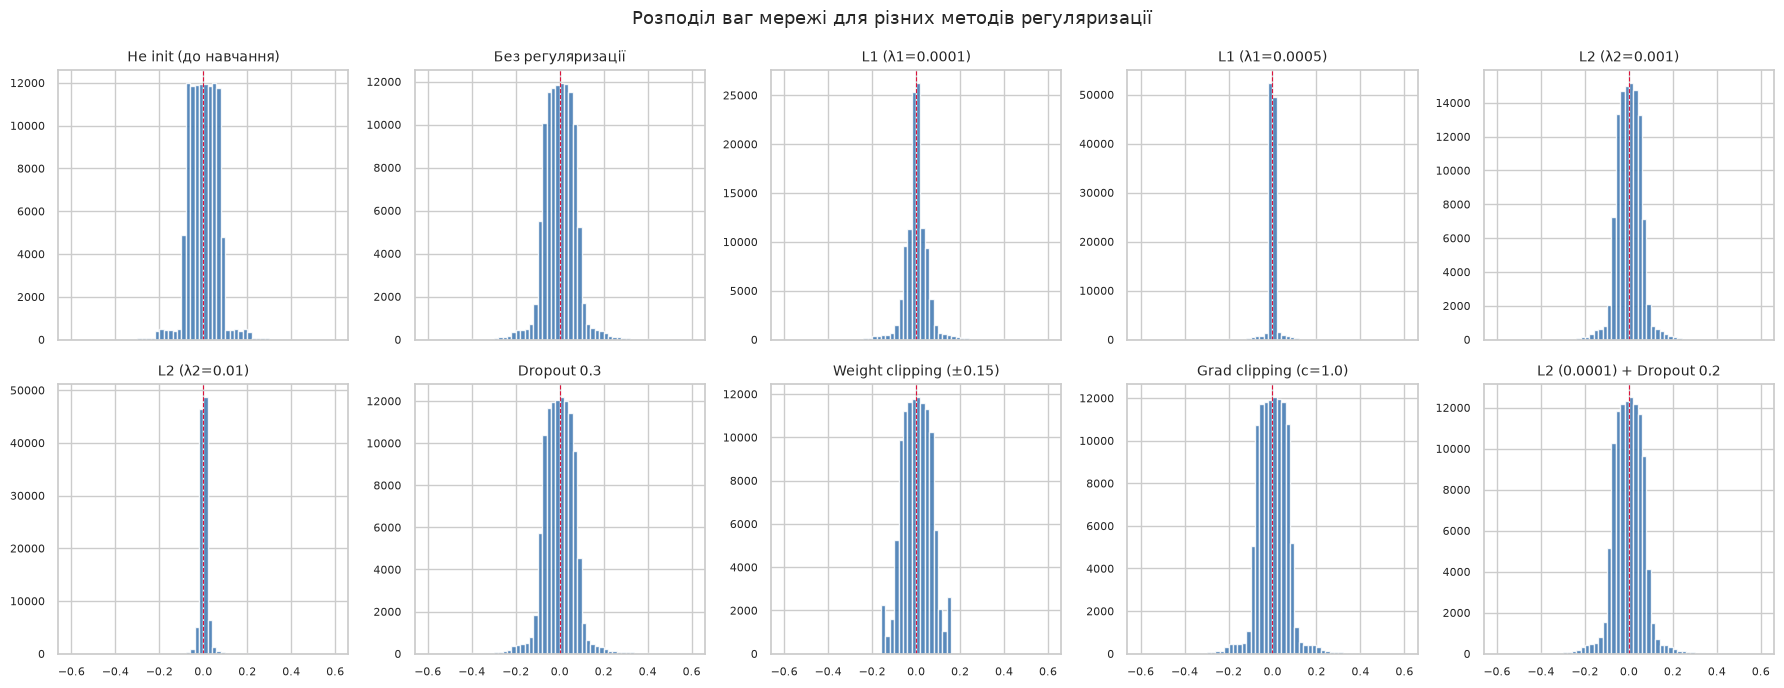

In [16]:
hist_items = [
    ("He init (до навчання)", init_weights),
    ("Без регуляризації", baseline_res["all_weights"]),
    (l1_results[1]["name"], l1_results[1]["all_weights"]),
    (l1_results[2]["name"], l1_results[2]["all_weights"]),
    (l2_results[1]["name"], l2_results[1]["all_weights"]),
    (l2_results[2]["name"], l2_results[2]["all_weights"]),
    (dropout_results[1]["name"], dropout_results[1]["all_weights"]),
    (wclip_tight["name"], wclip_tight["all_weights"]),
    (gclip_results[1]["name"], gclip_results[1]["all_weights"]),
    (combined_res["name"], combined_res["all_weights"]),
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharex=True, sharey=False)
for ax, (title, weights) in zip(axes.ravel(), hist_items):
    ax.hist(weights, bins=60, range=(-0.6, 0.6), color="#3b75af", alpha=0.85)
    ax.axvline(0.0, color="crimson", ls="--", lw=0.8)
    ax.set_title(title, fontsize=10)
    ax.tick_params(labelsize=8)

fig.suptitle("Розподіл ваг мережі для різних методів регуляризації", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "04_weight_distributions.png"), dpi=150)
plt.show()

**Аналіз розподілу ваг:**
- `L1` формує гострий пік у нулі зі зростанням $\lambda_1$, перетворюючи більшість малих ваг на майже нульові.
- `L2` рівномірно стискає дисперсію розподілу без формування такого різкого піку в нулі за помірних $\lambda_2$.
- Жорсткий `Weight clipping (±0.15)` утворює чіткі граничні піки на краях $[-0.15, 0.15]$.
- `Gradient clipping` та `Dropout` зберігають гладку форму розподілу, близьку до базової моделі.

## 3.3. Залежність мертвих нейронів від точності

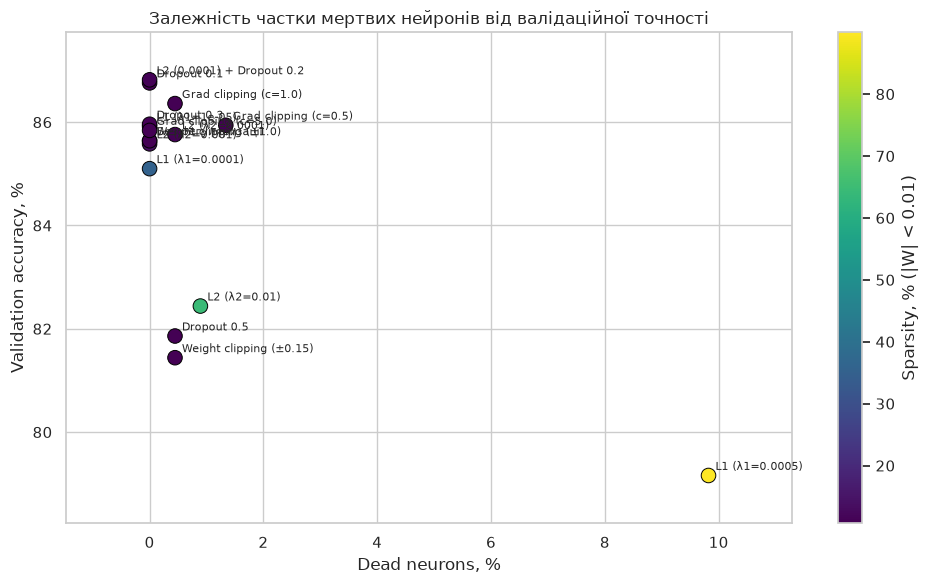

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
x_dead = [r["dead_overall"] for r in all_results]
y_acc = [r["val_acc"] for r in all_results]
c_sparsity = [r["sparsity_pct"] for r in all_results]

sc = ax.scatter(
    x_dead,
    y_acc,
    c=c_sparsity,
    cmap="viridis",
    s=110,
    edgecolors="black",
    linewidths=0.7,
    zorder=3,
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Sparsity, % (|W| < 0.01)")

for r in all_results:
    ax.annotate(
        r["name"],
        (r["dead_overall"], r["val_acc"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title("Залежність частки мертвих нейронів від валідаційної точності")
ax.set_xlabel("Dead neurons, %")
ax.set_ylabel("Validation accuracy, %")
ax.margins(x=0.15, y=0.12)
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "05_dead_neurons_vs_accuracy.png"), dpi=150)
plt.show()

## 3.4. Висновки та відповіді на дослідницькі питання

1. **Чи завжди збільшення сили регуляризації покращує узагальнювальну здатність?**
   Ні. Помірна регуляризація (`L2 = 1e-4`, `L1 = 1e-5`, `Grad clipping c=1.0`, `Dropout 0.1–0.3`) знижує перенавчання і покращує валідаційну точність порівняно з базовою моделлю. Надмірне посилення штрафів (`L1 = 5e-4`, `L2 = 1e-2`, `Dropout 0.5`, жорсткий `Weight clipping ±0.15`) переводить модель у режим **недонавчання**: ємність мережі падає, а валідаційна точність знижується.

2. **Вплив мертвих нейронів і розрідженості на точність:**
   - За помірних режимів кількість мертвих нейронів залишається близькою до 0%, а моделі з однаковою часткою мертвих нейронів можуть мати різну точність залежно від структури ваг (наприклад, `L1 1e-4` проти `Grad clipping c=1.0`).
   - Різке зростання кількості мертвих нейронів (як у `L1 = 5e-4`) безпосередньо супроводжується падінням точності через втрату пропускної здатності прихованих шарів.
   - Оптимальний баланс досягається при низькій або помірній розрідженості (~11–15%) і майже нульовій частці мертвих нейронів.

3. **Комбінована регуляризація (`L2 1e-4 + Dropout 0.2`):**
   Поєднання слабкої L2-регуляризації та помірного Dropout не погіршує збіжність, утримує кількість мертвих нейронів на мінімальному рівні та демонструє стабільний баланс між складністю моделі й точністю, без ефекту надмірного обмеження.

4. **Розмежування понять:**
   - **Мала величина ваг:** параметри мають невеликі за модулем значення, що обмежує чутливість виходу до коливань входу (типовий ефект `L2`).
   - **Нульова або майже нульова вага:** окремий зв'язок фактично вимкнений (`|W_ij| < 0.01`, метрика sparsity), але сам нейрон може залишатися активним завдяки іншим входам або зміщенню.
   - **Неактивний нейрон:** нейрон, що на конкретному об'єкті чи батчі має вихід $A_j \le 0$ (або тимчасово вимкнений маскою Dropout під час тренування).
   - **Мертвий нейрон:** нейрон із ReLU, чия передактивація $Z_j \le 0$ для **всіх** об'єктів вибірки, через що його градієнт тотожно дорівнює нулю і він не оновлюється.
   - **Надмірно регуляризована модель:** модель у стані недонавчання, коли штрафи чи обмеження не дають параметрам апроксимувати навіть базові закономірності навчальних даних.